In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [31]:
df=pd.read_csv('../data/online_retail.csv')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [32]:
df.shape
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


#Data Cleaning

In [33]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [34]:
df['InvoiceDate']=pd.to_datetime(df['InvoiceDate'])
df['Revenue']=df['Quantity']*df['UnitPrice']

In [35]:
df[df['Quantity'] < 0].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom,-27.50
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom,-4.65
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom,-19.80
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,-6.96
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,-6.96


In [38]:
df = df[df['Quantity'] > 0]
df = df.dropna(subset=['CustomerID'])
df.shape

(397924, 9)

In [39]:
df.duplicated().sum()

np.int64(5192)

In [40]:
df=df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

In [43]:
df['Revenue'].sum()

np.float64(8887208.894)

In [44]:
df['InvoiceNo'].nunique()

18536

In [45]:
df['CustomerID'].nunique()  

4339

In [47]:
total_revenue = df['Revenue'].sum()
total_orders = df['InvoiceNo'].nunique()
total_customers = df['CustomerID'].nunique()

print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")

Total Revenue: $8,887,208.89
Total Orders: 18,536
Total Customers: 4,339


In [49]:
df['Month']=df['InvoiceDate'].dt.to_period('M')
monthly_sales = df.groupby('Month')['Revenue'].sum()
monthly_sales.head()

Month
2010-12    570422.730
2011-01    568101.310
2011-02    446084.920
2011-03    594081.760
2011-04    468374.331
Freq: M, Name: Revenue, dtype: float64

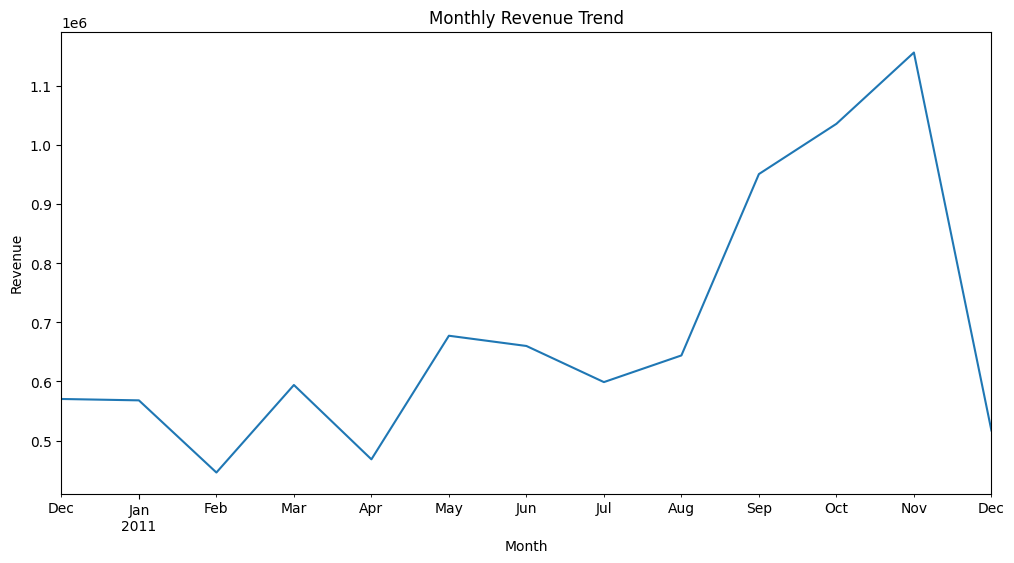

In [50]:
monthly_sales.plot(figsize=(12,6))

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')

plt.show()

In [54]:
top_products = df.groupby('Description')['Revenue'].sum()
top_products = top_products.sort_values(ascending=False)
top_products.head(10)

Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142264.75
WHITE HANGING HEART T-LIGHT HOLDER    100392.10
JUMBO BAG RED RETROSPOT                85040.54
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
POSTAGE                                77803.96
PARTY BUNTING                          68785.23
ASSORTED COLOUR BIRD ORNAMENT          56413.03
Manual                                 53419.93
RABBIT NIGHT LIGHT                     51251.24
Name: Revenue, dtype: float64

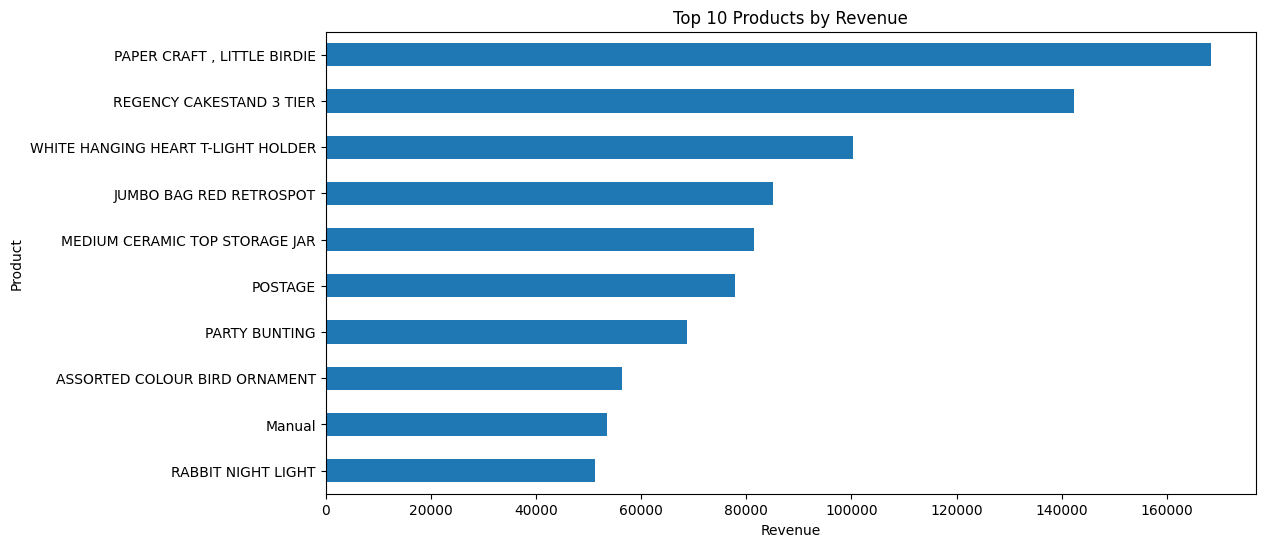

In [56]:
top_products.head(10).sort_values().plot(
    kind='barh',
    figsize=(12,6)
)

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Product')

plt.show()

In [58]:
customer_revenue=df.groupby('CustomerID')['Revenue'].sum()
customer_revenue = customer_revenue.sort_values(ascending=False)
customer_revenue.head(10)   

CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: Revenue, dtype: float64

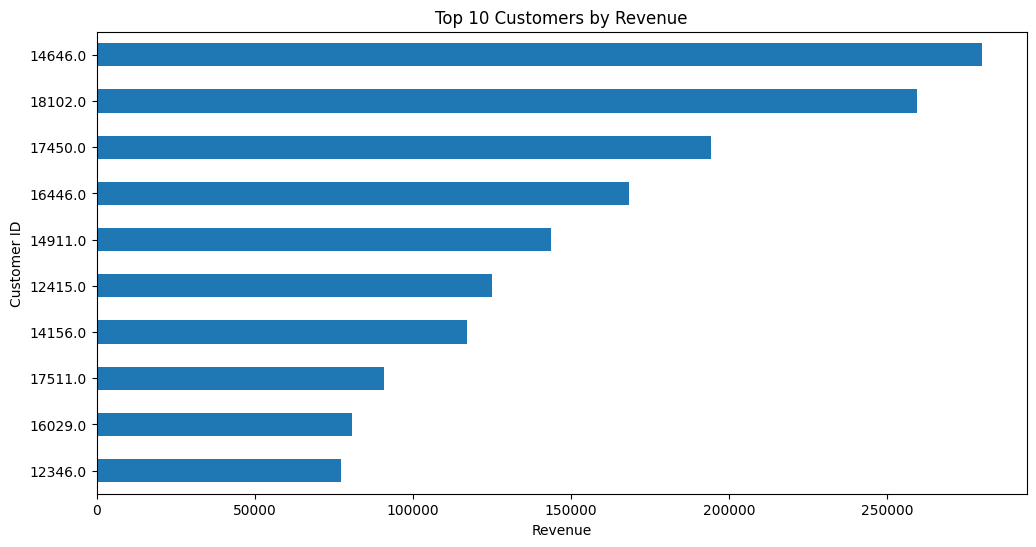

In [59]:
customer_revenue.head(10).sort_values().plot(
    kind='barh',
    figsize=(12,6)
)

plt.title('Top 10 Customers by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Customer ID')

plt.show()

In [60]:
customer_orders = df.groupby('CustomerID')['InvoiceNo'].nunique()
customer_orders.sort_values(ascending=False).head(10)


CustomerID
12748.0    210
14911.0    201
17841.0    124
13089.0     97
14606.0     93
15311.0     91
12971.0     86
14646.0     74
16029.0     63
13408.0     62
Name: InvoiceNo, dtype: int64

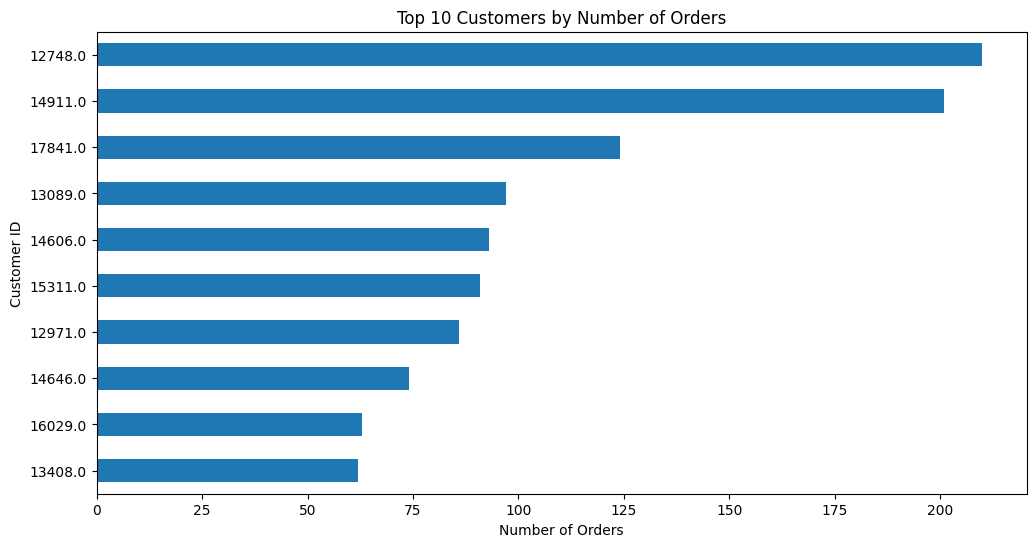

In [61]:
customer_orders.sort_values(ascending=False).head(10).sort_values().plot(
    kind='barh',
    figsize=(12,6)
)

plt.title('Top 10 Customers by Number of Orders')
plt.xlabel('Number of Orders')
plt.ylabel('Customer ID')

plt.show()

In [67]:
country_revenue = df.groupby('Country')['Revenue'].sum()
country_revenue = country_revenue.sort_values(ascending=False)
country_revenue.head(10)

Country
United Kingdom    7285024.644
Netherlands        285446.340
EIRE               265262.460
Germany            228678.400
France             208934.310
Australia          138453.810
Spain               61558.560
Switzerland         56443.950
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64

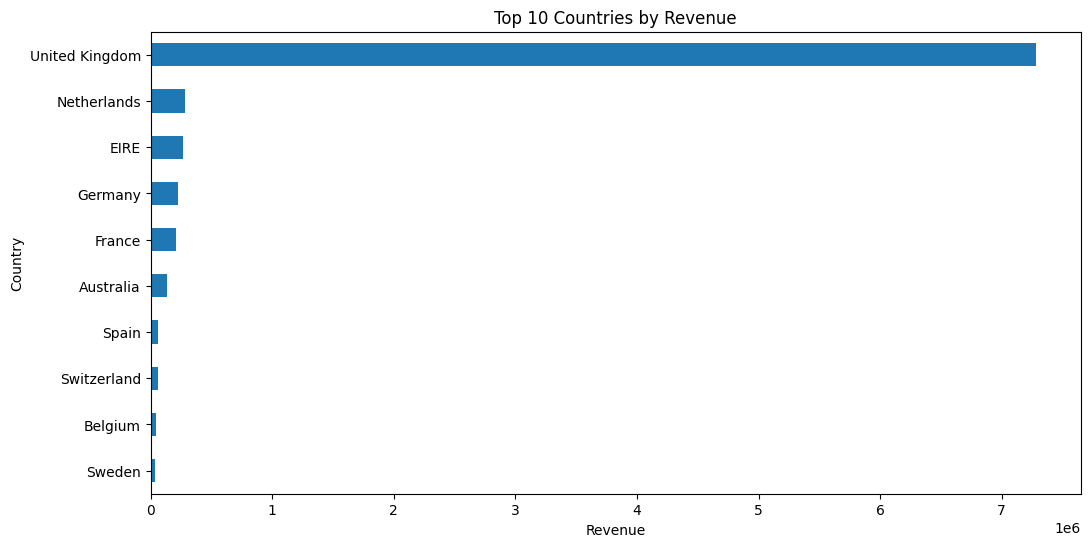

In [68]:
country_revenue.head(10).sort_values().plot(
    kind='barh',
    figsize=(12,6)
)

plt.title('Top 10 Countries by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Country')

plt.show()

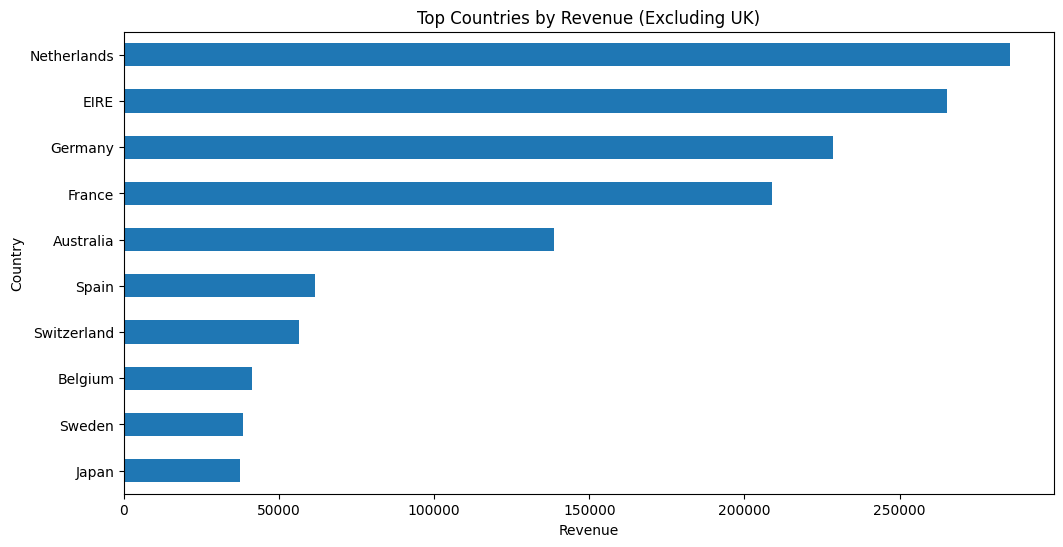

In [70]:
## International Revenue Analysis (Excluding UK)

non_uk = country_revenue[country_revenue.index != 'United Kingdom']

non_uk.head(10).sort_values().plot(
    kind='barh',
    figsize=(12,6)
)

plt.title('Top Countries by Revenue (Excluding UK)')
plt.xlabel('Revenue')
plt.ylabel('Country')

plt.show()


In [69]:
df.to_csv('../data/cleaned_retail_data.csv', index=False)